In [4]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black

import os

os.chdir("/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/scripts")
from reproject.mosaicking import find_optimal_celestial_wcs, reproject_and_coadd

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
import astropy.units as u
from astropy.io import fits, ascii
from astropy.stats import knuth_bin_width
from astropy.table import Table
from astropy.coordinates import SkyCoord
import phot_toolkit as PTK
import photometric_pipeline as PPL
import plot_toolkit as PLOT

working_directory = (
    "/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_2/mastDownload/JWST"
)
PHOTOMETRIC_pipeline = PPL.Pipeline_level_2_data(working_directory=working_directory)

level3_data_path = "/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_3/"

from astropy.visualization import (
    ZScaleInterval,
    AsinhStretch,
    ImageNormalize,
    make_lupton_rgb,
)

from matplotlib.colors import to_rgb

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black
Initialized filepaths for :  ['F187N', 'F335M', 'F115W', 'F277W', 'F200W', 'F444W', 'F182M', 'F430M', 'F090W', 'F356W', 'F150W', 'F480M', 'F212N']


In [5]:
filter = "F115W"
mode = "long"

pixel_coord_sources = {}
world_coord_sources = {}
magnitudes = {}
pixel_coord_sources[filter] = {}
world_coord_sources[filter] = {}
magnitudes[filter] = {}

(
    pixel_coord_sources[filter][mode],
    world_coord_sources[filter][mode],
    magnitudes[filter][mode],
) = PHOTOMETRIC_pipeline._collect_detections_mag_limited(
    filename_ap=f"/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_3/mosaic_{filter}_{mode}_exposure-ap.fits",
    filter=filter,
    detection_sigma=2.0,
)

In [14]:
catalogue_path = (
    "../Photometry/catalogue_jeroen/NGC346_NIRCam_and_MIRI_Public_JWST_Catalogue.fits"
)
Catalogue = PTK.Read_Catalogue(catalogue_path=catalogue_path).cat_data
Catalogue_ra_dec = SkyCoord(
    ra=Catalogue["RA"] * u.deg, dec=Catalogue["DEC"] * u.deg, frame="icrs"
)

In [17]:
world_coord_sources_sc = SkyCoord(
    ra=world_coord_sources[filter][mode][0] * u.deg,
    dec=world_coord_sources[filter][mode][1] * u.deg,
    frame="icrs",
)


idx, d2d, d3d = world_coord_sources_sc.match_to_catalog_sky(Catalogue_ra_dec)

array([24.14 , 17.072, 22.242, ..., 23.699, 27.51 , 25.175],
      shape=(87850,), dtype='>f8')

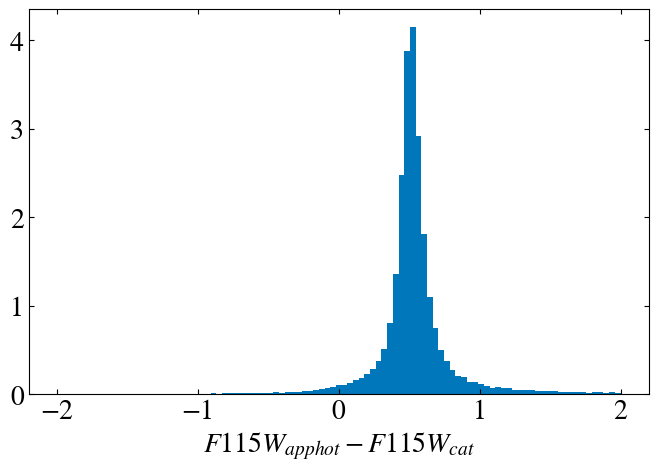

In [46]:
fig = plt.figure()
gs = fig.add_gridspec(1, 1, figure=fig, wspace=0, hspace=0)
ax0 = fig.add_subplot(gs[0, 0])

bins = np.linspace(-2, 2, 100)
ax0.hist(-Catalogue["F115W"][idx] + magnitudes[filter][mode], bins=bins, density=True)
ax0.set_xlabel(r"$F115W_{apphot} - F115W_{cat}$")
plt.show()

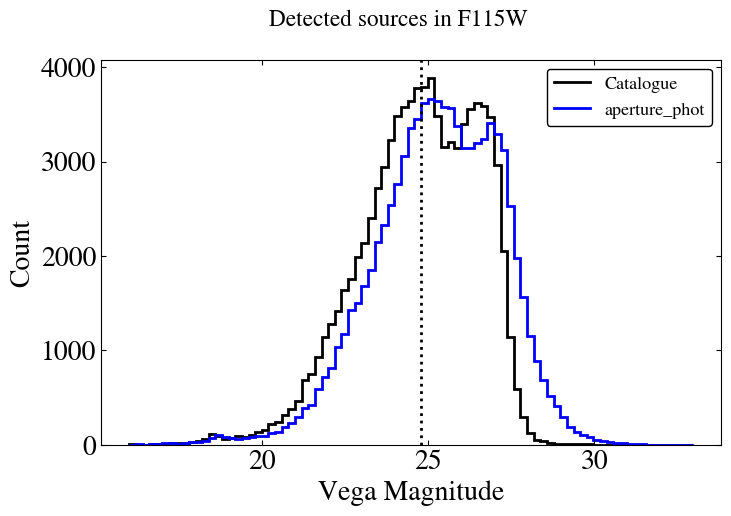

In [31]:
fig = plt.figure()
gs = fig.add_gridspec(1, 1, figure=fig, wspace=0, hspace=0)
ax0 = fig.add_subplot(gs[0, 0])

samples = Catalogue["F115W"][idx]

N_samples = len(samples)
dx, bin_edges = knuth_bin_width(samples, return_bins=True)
hist = np.histogram(samples, bins=bin_edges)[0]
ax0.stairs(
    hist,
    edges=bin_edges,
    fill=False,
    label=f"Catalogue",
    lw=2,
    edgecolor="black",
)


own_hist = np.histogram(magnitudes[filter][mode], bins=bin_edges)[0]
ax0.stairs(
    own_hist,
    edges=bin_edges,
    fill=False,
    label=f"aperture_phot",
    lw=2,
    edgecolor="blue",
)


ax0.legend()
ax0.set_xlabel("Vega Magnitude")
ax0.set_ylabel("Count")

ax0.axvline(x=24.8, label="completeness limit", c="black", lw=2, ls=":")
fig.suptitle(f"Detected sources in F115W ")
plt.show()